# AutoMetrics: Initial Exploratory Data Analysis
**CSC 3780 — Fundamentals of Data Science**

**Research question: Why are some car brands more expensive than others?**

We explore prices, brands, vehicle age, body type, and performance in our edited Kaggle dataset. This notebook looks for patterns. It does not change the original file, fill missing values, remove records, or build models. A relationship between two columns does not prove that one causes the other.

## 1. Import libraries
Pandas and NumPy help us work with data. Matplotlib and Seaborn help us make charts.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

## 2. Load the dataset
Read the first worksheet of our Excel file. The path below works when Jupyter starts in the `notebooks` folder or the project folder. We use `df` to refer to the data throughout the notebook.

In [2]:
try:
    df = pd.read_excel("../data/raw/cars_dataset_edited.csv.xlsx")
except FileNotFoundError:
    df = pd.read_excel("data/raw/cars_dataset_edited.csv.xlsx")

## 3. Display the first five rows
A quick preview helps us see how the dataset is organized.

In [3]:
df.head()

,vehicle_id,make,model,model_variant,model_year,vehicle_year,vehicle_age,body_type,brand_reputation_score,brand_reliability_score,...,torque_to_weight_ratio,handling_score,acceleration_score,braking_score,performance_score,reliability_score,original_price,msrp,total_feature_count,safety_feature_count
0,V00000001,BMW,i4,i4 RS,2020,2020,6,Sedan,88,78,...,311.439026,35.2,71.1,94.9,65.4,72.3,54950.99,56204.07,31,12
1,V00000002,Chevrolet,Equinox,Equinox SE,2016,2016,10,SUV,78,76,...,155.944885,35.9,77.3,57.8,66.2,52.7,24526.91,25741.61,21,9
2,V00000003,Kia,Sportage,Sportage M Sport,2024,2024,2,SUV,83,86,...,163.426372,41.1,78.3,86.0,65.9,78.2,26483.37,27482.64,18,8
3,V00000004,Hyundai,Ioniq 5,Ioniq 5 Sport,2015,2015,11,SUV,84,87,...,162.831227,40.3,60.7,73.3,62.4,71.6,53048.43,53061.91,37,15
4,V00000005,Honda,Accord,Accord GT,2022,2022,4,Sedan,90,92,...,262.573882,40.8,77.5,68.2,62.0,92.3,29120.61,29362.80,19,7


## 4. Check dataset dimensions and column names
Check how many rows and columns we have and list the available variables.

In [4]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("Column names:")
print(df.columns.tolist())

Rows: 100000
Columns: 26
Column names:
['vehicle_id', 'make', 'model', 'model_variant', 'model_year', 'vehicle_year', 'vehicle_age', 'body_type', 'brand_reputation_score', 'brand_reliability_score', 'brand_premium_index', 'top_speed_kmh', 'zero_to_100_kmh_seconds', 'zero_to_60_mph_seconds', 'quarter_mile_seconds', 'power_to_weight_ratio', 'torque_to_weight_ratio', 'handling_score', 'acceleration_score', 'braking_score', 'performance_score', 'reliability_score', 'original_price', 'msrp', 'total_feature_count', 'safety_feature_count']


The dataset has **100,000 rows and 26 columns**. Each row describes a vehicle record. We still need the original source documentation to confirm how these records were collected or created.

## 5. Check data types and missing values
Data types tell us which columns contain numbers or text. Missing values matter because summaries and charts use the available values.

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 26 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   vehicle_id               100000 non-null  str    
 1   make                     100000 non-null  str    
 2   model                    100000 non-null  str    
 3   model_variant            98000 non-null   str    
 4   model_year               100000 non-null  int64  
 5   vehicle_year             100000 non-null  int64  
 6   vehicle_age              100000 non-null  int64  
 7   body_type                100000 non-null  str    
 8   brand_reputation_score   100000 non-null  int64  
 9   brand_reliability_score  100000 non-null  int64  
 10  brand_premium_index      100000 non-null  int64  
 11  top_speed_kmh            100000 non-null  float64
 12  zero_to_100_kmh_seconds  100000 non-null  float64
 13  zero_to_60_mph_seconds   100000 non-null  float64
 14  quarter_mile_sec

In [6]:
df.isna().sum()

vehicle_id                    0
make                          0
model                         0
model_variant              2000
model_year                    0
vehicle_year                  0
vehicle_age                   0
body_type                     0
brand_reputation_score        0
brand_reliability_score       0
brand_premium_index           0
top_speed_kmh                 0
zero_to_100_kmh_seconds       0
zero_to_60_mph_seconds        0
quarter_mile_seconds          0
power_to_weight_ratio         0
torque_to_weight_ratio        0
handling_score                0
acceleration_score            0
braking_score                 0
performance_score             0
reliability_score          2000
original_price             1000
msrp                       2000
total_feature_count           0
safety_feature_count          0
dtype: int64

There are **1,000 missing original prices (1%)**. MSRP, reliability score, and model variant each have **2,000 missing values (2%)**. The other columns have no missing values detected by Pandas. We leave these values missing. Price summaries will therefore use fewer than 100,000 values.

We will also check whether either price column contains zero or negative values.

In [7]:
for column in ["original_price", "msrp"]:
    print(column)
    print("Missing:", df[column].isna().sum())
    print("Zero:", (df[column] == 0).sum())
    print("Negative:", (df[column] < 0).sum())
    print()

original_price
Missing: 1000
Zero: 0
Negative: 0

msrp
Missing: 2000
Zero: 0
Negative: 0



Both price columns have **no zero or negative values** among the recorded prices.

## 6. Check for duplicate records
Count repeated rows and repeated vehicle IDs. We are checking only, not deleting anything.

In [8]:
print("Duplicate rows:", df.duplicated().sum())
print("Repeated vehicle IDs:", df["vehicle_id"].duplicated().sum())

Duplicate rows: 0
Repeated vehicle IDs: 0


There are **no exact duplicate rows or repeated vehicle IDs**. This check alone cannot confirm that every row represents a different real-world vehicle.

## 7. Display summary statistics
Look at counts, averages, spread, and minimum and maximum values. We then focus on the variables most relevant to our question.

In [9]:
df.describe().round(2)

,model_year,vehicle_year,vehicle_age,brand_reputation_score,brand_reliability_score,brand_premium_index,top_speed_kmh,zero_to_100_kmh_seconds,zero_to_60_mph_seconds,quarter_mile_seconds,...,torque_to_weight_ratio,handling_score,acceleration_score,braking_score,performance_score,reliability_score,original_price,msrp,total_feature_count,safety_feature_count
count,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,...,100000.00,100000.00,100000.00,100000.0,100000.00,98000.00,99000.00,98000.00,100000.00,100000.00
mean,2020.61,2020.61,5.39,85.72,84.33,48.02,171.60,8.53,8.10,15.30,...,241.38,48.54,74.43,69.9,64.29,73.58,40382.10,41391.31,22.61,9.34
std,4.08,4.08,4.08,4.55,6.62,18.22,41.08,2.95,2.80,2.18,...,125.70,12.98,10.13,14.7,9.54,11.66,22560.27,23117.40,7.69,2.80
min,2011.00,2011.00,0.00,78.00,76.00,32.00,80.00,2.20,2.09,9.00,...,39.15,10.00,37.90,10.0,25.90,25.10,12076.30,12094.06,7.00,1.00
25%,2018.00,2018.00,2.00,82.00,78.00,38.00,141.90,6.65,6.32,14.03,...,153.83,39.60,67.20,59.9,57.70,65.70,26716.14,27376.37,17.00,7.00
50%,2021.00,2021.00,5.00,85.00,82.00,40.00,166.40,8.80,8.36,15.54,...,211.06,48.00,73.80,70.0,64.10,73.90,34168.30,35056.12,20.00,9.00
75%,2024.00,2024.00,8.00,90.00,92.00,50.00,194.40,10.67,10.13,16.86,...,292.64,56.80,81.10,80.1,70.60,81.90,44909.58,46050.91,28.00,11.00
max,2026.00,2026.00,15.00,93.00,95.00,90.00,330.00,18.21,17.30,22.03,...,1182.06,100.00,100.00,100.0,100.00,100.00,198709.38,208363.82,48.00,19.00


In [10]:
important_columns = ["original_price", "msrp", "vehicle_age", "performance_score",
                     "reliability_score", "braking_score", "handling_score"]
df[important_columns].describe().round(2)

,original_price,msrp,vehicle_age,performance_score,reliability_score,braking_score,handling_score
count,99000.00,98000.00,100000.00,100000.00,98000.00,100000.0,100000.00
mean,40382.10,41391.31,5.39,64.29,73.58,69.9,48.54
std,22560.27,23117.40,4.08,9.54,11.66,14.7,12.98
min,12076.30,12094.06,0.00,25.90,25.10,10.0,10.00
25%,26716.14,27376.37,2.00,57.70,65.70,59.9,39.60
50%,34168.30,35056.12,5.00,64.10,73.90,70.0,48.00
75%,44909.58,46050.91,8.00,70.60,81.90,80.1,56.80
max,198709.38,208363.82,15.00,100.00,100.00,100.0,100.00


Original prices range from **12,076.30 to 198,709.38**, with a median of **34,168.30**. MSRP ranges from **12,094.06 to 208,363.82**. The price currency has not been confirmed, so charts use “dataset units.” High prices are worth checking, but they are not automatically mistakes.

Vehicle ages range from **0 to 15 years**. Performance scores range from **25.9 to 100**, reliability from **25.1 to 100**, and braking and handling from **10 to 100**. We need documentation to understand how the scores were made. Some scores reach 100, which may be a cap.

## 8. Explore car prices across brands
Compare how many records each brand has and its median original price. The median is the middle price and is less affected by unusually expensive cars than the mean. We use original price consistently for the remaining charts; its exact meaning still needs confirmation.

In [11]:
print("Number of brands:", df["make"].nunique())
print("Number of models:", df["model"].nunique())
df["make"].value_counts()

Number of brands: 13
Number of models: 129


make
Toyota           13085
Ford             12543
Honda            10701
Chevrolet         9934
Nissan            8285
Volkswagen        7910
Hyundai           7505
Kia               6757
Mercedes-Benz     6031
BMW               5395
Audi              4334
Lexus             3832
Mazda             3688
Name: count, dtype: int64

In [12]:
brand_prices = df.groupby("make")["original_price"].agg(["count", "mean", "median"])
brand_prices.sort_values("median").round(2)

,count,mean,median
make,,,
Hyundai,7424,32631.41,27847.14
Mazda,3648,28987.19,28055.37
Nissan,8203,36878.63,28929.08
Honda,10570,30680.01,29569.10
Kia,6686,31766.61,30293.39
Toyota,12959,37187.82,31094.55
Ford,12438,31753.27,32427.20
Volkswagen,7827,33548.15,33461.39
Chevrolet,9842,38351.57,33479.09


There are **13 brands and 129 model names**. Toyota has the most rows (13,085) and Mazda the fewest (3,688), so brands are not equally represented. The table's `count` includes only recorded original prices.

Mercedes-Benz has the highest median original price (**64,564.95**), followed by BMW (**62,045.96**). Hyundai has the lowest (**about 27,847.14**). These are overall comparisons; brands may offer different mixes of vehicles.

## 9. Explore relationships with age, body type, and performance
Compare typical prices by age and body type. Correlation gives a simple measure of how two numeric columns move together: positive values indicate that they tend to increase together, and negative values indicate opposite directions. Correlation does not explain why the pattern exists.

In [13]:
df.groupby("vehicle_age")["original_price"].median().round(2)

vehicle_age
0     34247.75
1     34190.90
2     34143.71
3     33905.41
4     34622.16
5     34409.55
6     33867.88
7     34352.02
8     33961.27
9     34159.86
10    34277.59
11    33709.12
12    34481.98
13    33947.35
14    34154.49
15    34109.53
Name: original_price, dtype: float64

In [14]:
body_prices = df.groupby("body_type")["original_price"].agg(["count", "median"])
body_prices.sort_values("median").round(2)

,count,median
body_type,,
Hatchback,14449,22963.19
Crossover,3313,25081.19
Sedan,22479,28484.61
Pickup,8482,33223.76
Minivan,3203,35153.74
SUV,36161,37472.55
Van,1273,40021.71
Convertible,856,47085.26
Coupe,8784,51041.15


In [15]:
relationship_columns = ["original_price", "vehicle_age", "performance_score",
                        "reliability_score", "safety_feature_count"]
df[relationship_columns].corr().round(3)

,original_price,vehicle_age,performance_score,reliability_score,safety_feature_count
original_price,1.000,-0.004,0.358,-0.131,0.488
vehicle_age,-0.004,1.000,-0.002,-0.696,-0.163
performance_score,0.358,-0.002,1.000,-0.099,0.171
reliability_score,-0.131,-0.696,-0.099,1.000,0.001
safety_feature_count,0.488,-0.163,0.171,0.001,1.000


**What we see:** Median prices stay close to 34,000 across ages, and the price–age correlation is about **−0.004**, which is close to zero. This does not show a clear overall age trend. It also does not tell us how a car loses value over time, since we have not confirmed what “original price” means.

Coupes have the highest median price by body type (**51,041.15**), while hatchbacks have the lowest (**22,963.19**). Performance has a positive correlation with price (**0.358**): higher scores tend to go with higher prices, but there is plenty of variation. Safety-feature count also has a positive correlation (**0.488**). These patterns may partly reflect the kinds of vehicles each brand offers.

We should also avoid treating repeated information as separate evidence. The following checks show how year, age, and the two prices overlap.

In [16]:
print("Model year always matches vehicle year:",
      (df["model_year"] == df["vehicle_year"]).all())
print("Age always equals 2026 minus model year:",
      (df["vehicle_age"] == 2026 - df["model_year"]).all())
df[["original_price", "msrp"]].corr().round(4)

Model year always matches vehicle year: True
Age always equals 2026 minus model year: True


,original_price,msrp
original_price,1.0000,0.9996
msrp,0.9996,1.0000


The two year columns match, and age is calculated using **2026**. These columns repeat the same information. Original price and MSRP are also almost perfectly correlated (**about 0.9996**), so they are not independent pieces of evidence.

The premium index needs extra care: its name suggests a brand's price level, but we do not know how it was created.

In [17]:
df.groupby("make")["brand_premium_index"].nunique()

make
Audi             1
BMW              1
Chevrolet        1
Ford             1
Honda            1
Hyundai          1
Kia              1
Lexus            1
Mazda            1
Mercedes-Benz    1
Nissan           1
Toyota           1
Volkswagen       1
Name: brand_premium_index, dtype: int64

Every brand has just **one premium index value**. If that number was based on prices, using it to explain prices would be circular reasoning: “the brand costs more because it was labeled expensive.” We cannot confirm this from the file alone, so we do not use the index as an explanation.

We also cannot tell which earlier edits changed the data without the original download or an editing log. Missing prices, possible score caps, and unequal brand counts should stay visible in our discussion. We should not automatically remove expensive cars, since that could hide the differences we want to study.

## 10. Create basic visualizations
These charts help us compare prices and look for possible explanations. All recorded prices remain in the analysis. Scatterplots use small, transparent points so overlapping records are easier to see.

### Histogram: how are prices distributed?
This shows whether most prices are concentrated in one range and whether there is a long expensive tail.

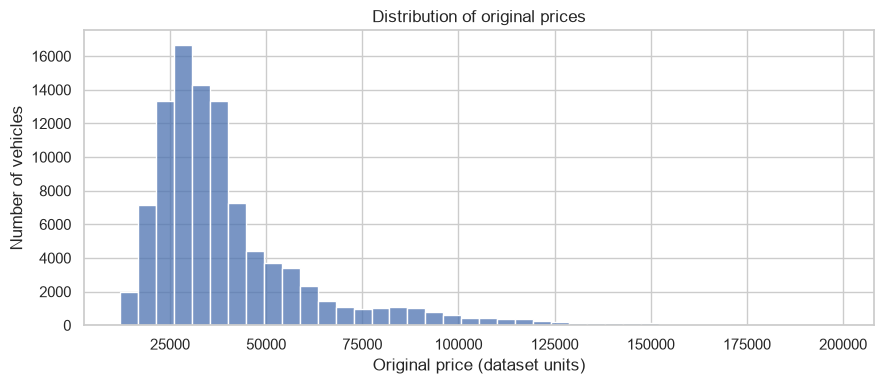

In [18]:
plt.figure(figsize=(9, 4))
sns.histplot(data=df, x="original_price", bins=40)
plt.title("Distribution of original prices")
plt.xlabel("Original price (dataset units)")
plt.ylabel("Number of vehicles")
plt.tight_layout()
plt.show()

### Bar chart: median price by brand
Compare the middle price for each brand.

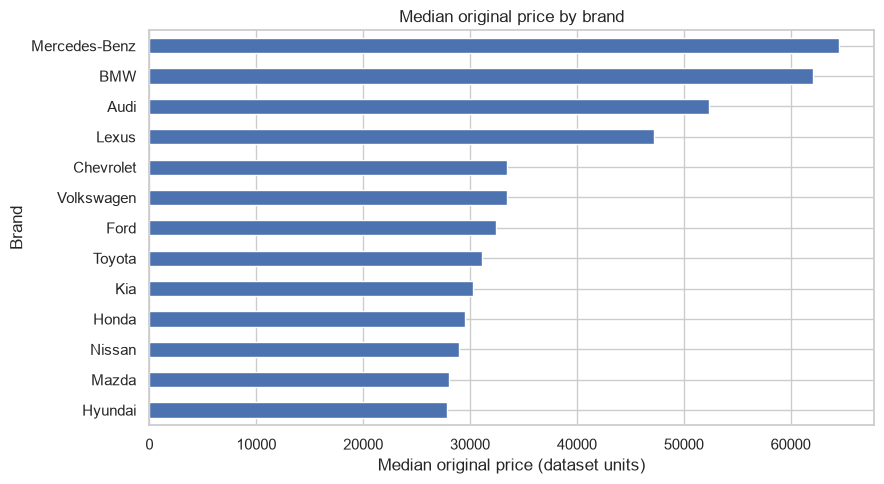

In [19]:
plt.figure(figsize=(9, 5))
brand_prices["median"].sort_values().plot(kind="barh")
plt.title("Median original price by brand")
plt.xlabel("Median original price (dataset units)")
plt.ylabel("Brand")
plt.tight_layout()
plt.show()

### Boxplot: price differences by body type
The box shows the middle half of prices, and the line inside shows the median. Points beyond the whiskers are unusual values, not necessarily errors. Brands with different body-type mixes may have different overall prices.

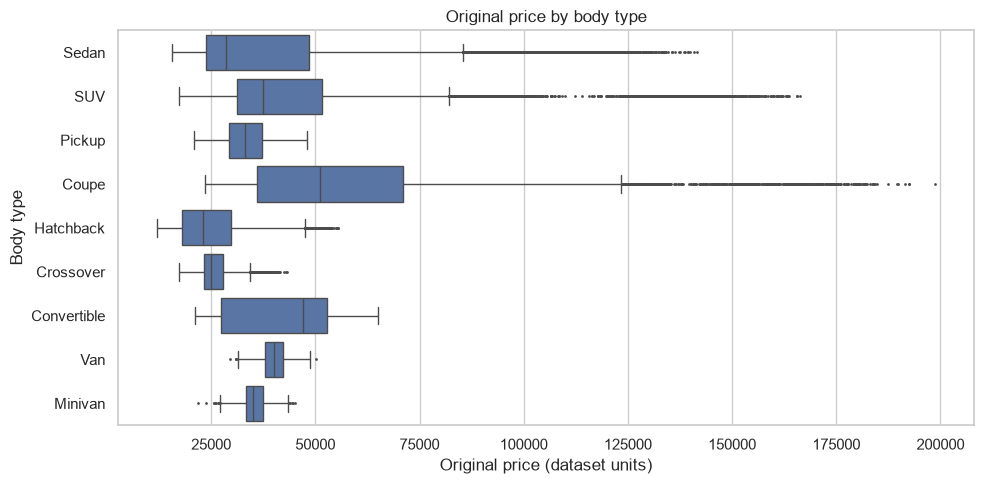

In [20]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x="original_price", y="body_type", fliersize=1)
plt.title("Original price by body type")
plt.xlabel("Original price (dataset units)")
plt.ylabel("Body type")
plt.tight_layout()
plt.show()

### Scatterplot: price and vehicle age
Look for an overall age pattern and notice the wide range of prices at each age. We should not assume this column measures current used-car sale prices.

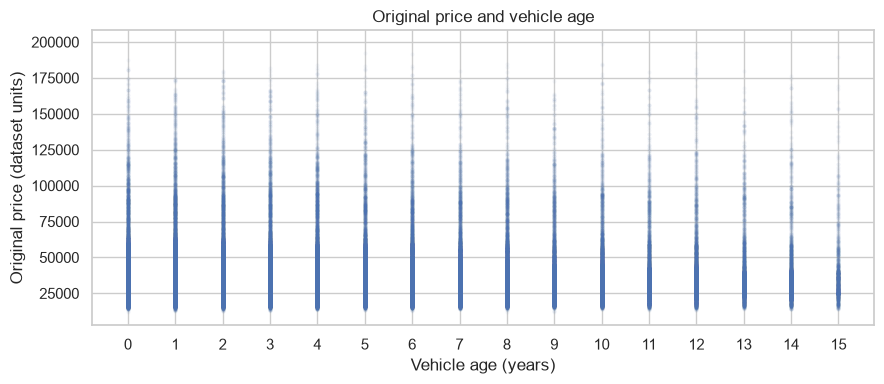

In [21]:
plt.figure(figsize=(9, 4))
sns.scatterplot(data=df, x="vehicle_age", y="original_price", alpha=0.05, s=8, linewidth=0)
plt.title("Original price and vehicle age")
plt.xlabel("Vehicle age (years)")
plt.ylabel("Original price (dataset units)")
plt.xticks(np.arange(0, 16, 1))
plt.tight_layout()
plt.show()

### Scatterplot: price and performance
Look for whether higher performance scores tend to go with higher prices. This is an overall pattern and may also reflect differences between brands and body types.

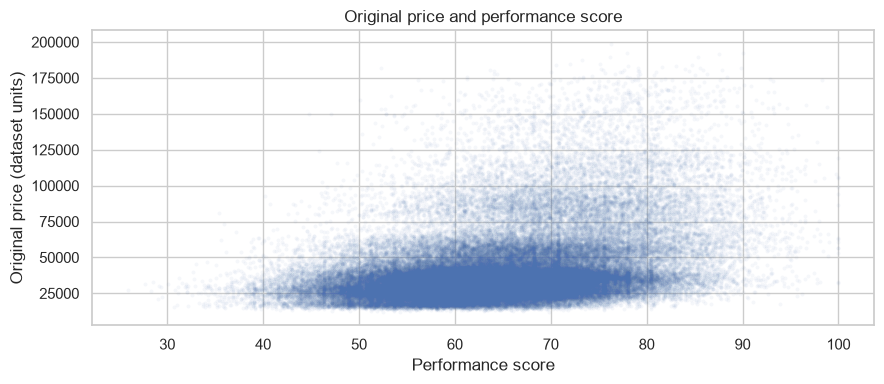

In [22]:
plt.figure(figsize=(9, 4))
sns.scatterplot(data=df, x="performance_score", y="original_price", alpha=0.05, s=8, linewidth=0)
plt.title("Original price and performance score")
plt.xlabel("Performance score")
plt.ylabel("Original price (dataset units)")
plt.tight_layout()
plt.show()

## 11. Summarize findings
- **Brands differ in price.** Mercedes-Benz and BMW have the highest median original prices, while Hyundai has the lowest in this dataset.
- **Body type and performance may help explain differences.** Coupes have the highest median price by body type, and higher performance scores tend to go with higher prices. These overall comparisons do not separate brand effects from vehicle characteristics.
- **Age shows little overall price relationship here.** The correlation is close to zero; this should not be interpreted as proof that cars do not depreciate.
- **Prices vary widely.** A smaller group of very expensive cars stretches the price distribution to the right. These records have been kept.
- **Missing values remain.** Original price is missing for 1% of rows; MSRP, reliability score, and model variant are each missing for 2%. No exact duplicate rows were found.
- **Some columns repeat information.** Age is based on the year 2026, the two year columns match, and original price and MSRP are very closely related.
- **The premium index needs a source.** It is fixed within each brand and might already include assumptions about price. It should not be treated as a proven reason for higher prices.
- **These are patterns, not causes.** We need the dataset source, price definitions, score definitions, and editing history before drawing stronger conclusions. A useful next step is comparing brands with similar body types and years.

No missing prices were filled, no records were removed, and no models were built. The original workbook was only read.